In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

print("Versi Python :", sys.version.split()[0])
print("Versi NumPy  :", np.__version__)
np.set_printoptions(precision=4, suppress=True)

Versi Python : 3.13.16
Versi NumPy  : 2.1.3


## 2. Memahami Tensor

Tensor adalah bentuk umum skalar, vektor, dan matriks.

- Skalar mempunyai 0 dimensi.
- Vektor mempunyai 1 dimensi.
- Matriks mempunyai 2 dimensi.
- Tensor juga dapat memiliki lebih dari 2 dimensi.

Kelas `Tensor` pertama yang diperkenalkan buku membungkus `np.array` dan menyediakan operasi `+`. Kita mulai dari bentuk dasar itu **sebelum membuat kelas yang lebih lengkap**.

In [2]:
class TensorDasar:
    def __init__(self, data):
        self.data = np.array(data)

    def __add__(self, other):
        return TensorDasar(self.data + other.data)

    def __repr__(self):
        return repr(self.data)

x_dasar = TensorDasar([1, 2, 3, 4, 5])
y_dasar = x_dasar + x_dasar
print("x =", x_dasar)
print("x + x =", y_dasar)
print("Bentuk:", x_dasar.data.shape)
assert np.array_equal(y_dasar.data, [2, 4, 6, 8, 10])

x = array([1, 2, 3, 4, 5])
x + x = array([ 2,  4,  6,  8, 10])
Bentuk: (5,)


## 3. *Autograd* dan grafik komputasi dinamis

Pada jaringan tanpa *autograd*, gradien setiap bobot dihitung dan disalurkan secara manual. Di sini, setiap operasi membuat **tensor hasil yang mengingat tensor penyusunnya**.

Contohnya:

```text
   a ----\\
           (+) ---- c
   b ----/
```

Jika `c = a + b`, turunan `c` terhadap `a` dan terhadap `b` sama-sama 1. Maka saat gradien `c` bernilai 1, setiap masukan menerima 1. Saat `b` digunakan di lebih dari satu jalur, seluruh kontribusi gradien **harus dijumlahkan**.

**Catatan penerapan:** Buku mengenalkan penghitung jumlah anak tensor untuk menunggu kontribusi gradien. Implementasi di bawah mencapai tujuan yang sama memakai **penelusuran grafik secara topologis**, sehingga gradien setiap cabang terkumpul sebelum diteruskan ke pendahulunya. Ini adalah penyesuaian implementasi, bukan perubahan konsep.

In [3]:
def _samakan_bentuk_gradien(grad, bentuk_tujuan):
    """Jumlahkan sumbu hasil penyiaran (broadcasting) agar gradien cocok."""
    grad = np.asarray(grad, dtype=float)
    while grad.ndim > len(bentuk_tujuan):
        grad = grad.sum(axis=0)
    for sumbu, ukuran in enumerate(bentuk_tujuan):
        if ukuran == 1 and grad.shape[sumbu] != 1:
            grad = grad.sum(axis=sumbu, keepdims=True)
    return grad.reshape(bentuk_tujuan)

class Tensor:
    """Tensor NumPy dengan grafik gradien otomatis sederhana (untuk pembelajaran)."""

    def __init__(self, data, autograd=False, creators=None, creation_op=None):
        # Parameter yang perlu dilatih direpresentasikan dalam floating point.
        if isinstance(data, Tensor):
            data = data.data
        self.data = np.array(data, dtype=float if autograd else None)
        self.autograd = bool(autograd)
        self.creators = list(creators) if creators else []
        self.creation_op = creation_op
        self.grad = None
        self._backward = lambda: None

    def __repr__(self):
        return f"Tensor({self.data!r}, autograd={self.autograd})"

    def __str__(self):
        return str(self.data)

    def _tambah_grad(self, tambahan):
        if not self.autograd:
            return
        tambahan = np.asarray(tambahan, dtype=float)
        tambahan = _samakan_bentuk_gradien(tambahan, self.data.shape)
        if self.grad is None:
            self.grad = Tensor(tambahan)
        else:
            self.grad.data += tambahan

    @staticmethod
    def _tensor_lain(other):
        return other if isinstance(other, Tensor) else Tensor(other)

    def backward(self, grad=None):
        """Bangun urutan topologis, lalu alirkan gradien dari keluaran ke parameter."""
        if not self.autograd:
            raise ValueError("Tensor ini tidak mengaktifkan autograd.")
        if grad is None:
            grad = np.ones_like(self.data, dtype=float)
        elif isinstance(grad, Tensor):
            grad = grad.data
        grad = np.asarray(grad, dtype=float)
        if grad.shape != self.data.shape:
            raise ValueError("Bentuk gradien awal harus sama dengan bentuk keluaran.")

        urutan, dikunjungi = [], set()
        def kunjungi(node):
            if id(node) in dikunjungi:
                return
            dikunjungi.add(id(node))
            for induk in node.creators:
                if induk.autograd:
                    kunjungi(induk)
            urutan.append(node)
        kunjungi(self)

        # Bersihkan gradien simpul perantara; gradien parameter disimpan
        # sampai optimizer.step()/optimizer.zero() mengosongkannya.
        for node in urutan:
            if node.creators:
                node.grad = None
        self._tambah_grad(grad)
        for node in reversed(urutan):
            node._backward()

    def __add__(self, other):
        other = self._tensor_lain(other)
        out = Tensor(self.data + other.data,
                     self.autograd or other.autograd,
                     [self, other], "add")
        def turunan():
            self._tambah_grad(out.grad.data)
            other._tambah_grad(out.grad.data)
        out._backward = turunan
        return out

    def __radd__(self, other):
        return self + other

    def __neg__(self):
        out = Tensor(-self.data, self.autograd, [self], "neg")
        out._backward = lambda: self._tambah_grad(-out.grad.data)
        return out

    def __sub__(self, other):
        return self + (-self._tensor_lain(other))

    def __rsub__(self, other):
        return self._tensor_lain(other) - self

    def __mul__(self, other):
        other = self._tensor_lain(other)
        out = Tensor(self.data * other.data,
                     self.autograd or other.autograd,
                     [self, other], "mul")
        def turunan():
            self._tambah_grad(out.grad.data * other.data)
            other._tambah_grad(out.grad.data * self.data)
        out._backward = turunan
        return out

    def __rmul__(self, other):
        return self * other

    def sum(self, dim=None):
        out = Tensor(self.data.sum(axis=dim), self.autograd, [self], f"sum_{dim}")
        def turunan():
            g = out.grad.data
            if dim is not None:
                g = np.expand_dims(g, axis=dim)
            self._tambah_grad(np.broadcast_to(g, self.data.shape))
        out._backward = turunan
        return out

    def expand(self, dim, copies):
        nilai = np.repeat(np.expand_dims(self.data, dim), copies, axis=dim)
        out = Tensor(nilai, self.autograd, [self], f"expand_{dim}")
        out._backward = lambda: self._tambah_grad(out.grad.data.sum(axis=dim))
        return out

    def transpose(self):
        out = Tensor(self.data.T, self.autograd, [self], "transpose")
        out._backward = lambda: self._tambah_grad(out.grad.data.T)
        return out

    def mm(self, other):
        other = self._tensor_lain(other)
        if self.data.ndim != 2 or other.data.ndim != 2:
            raise ValueError("Operasi mm pada contoh ini menggunakan matriks 2D.")
        out = Tensor(self.data @ other.data,
                     self.autograd or other.autograd,
                     [self, other], "mm")
        def turunan():
            self._tambah_grad(out.grad.data @ other.data.T)
            other._tambah_grad(self.data.T @ out.grad.data)
        out._backward = turunan
        return out

    def sigmoid(self):
        z = np.clip(self.data, -500, 500)
        hasil = 1 / (1 + np.exp(-z))
        out = Tensor(hasil, self.autograd, [self], "sigmoid")
        out._backward = lambda: self._tambah_grad(out.grad.data * hasil * (1 - hasil))
        return out

    def tanh(self):
        hasil = np.tanh(self.data)
        out = Tensor(hasil, self.autograd, [self], "tanh")
        out._backward = lambda: self._tambah_grad(out.grad.data * (1 - hasil**2))
        return out

    def relu(self):
        hasil = np.maximum(0, self.data)
        out = Tensor(hasil, self.autograd, [self], "relu")
        out._backward = lambda: self._tambah_grad(out.grad.data * (self.data > 0))
        return out

    def index_select(self, indices):
        indices = self._tensor_lain(indices)
        posisi = np.asarray(indices.data, dtype=int)
        if not np.array_equal(posisi, indices.data):
            raise ValueError("Indeks harus bilangan bulat.")
        out = Tensor(self.data[posisi], self.autograd, [self], "index_select")
        def turunan():
            g = np.zeros_like(self.data, dtype=float)
            np.add.at(g, posisi, out.grad.data)  # Indeks berulang tetap terakumulasi
            self._tambah_grad(g)
        out._backward = turunan
        return out

    def cross_entropy(self, target_indices):
        """Entropi silang klasifikasi 2D; target berisi indeks kelas benar."""
        target = self._tensor_lain(target_indices)
        if self.data.ndim != 2:
            raise ValueError("Logit harus berbentuk (jumlah_data, jumlah_kelas).")
        label = np.asarray(target.data).reshape(-1).astype(int)
        if len(label) != self.data.shape[0]:
            raise ValueError("Jumlah label harus sesuai dengan jumlah data.")
        if label.min() < 0 or label.max() >= self.data.shape[1]:
            raise ValueError("Ada label di luar rentang kelas.")
        logit_aman = self.data - self.data.max(axis=1, keepdims=True)
        eks = np.exp(logit_aman)
        peluang = eks / eks.sum(axis=1, keepdims=True)
        n = len(label)
        rugi = -np.log(np.maximum(peluang[np.arange(n), label], 1e-300)).mean()
        out = Tensor(rugi, self.autograd, [self], "cross_entropy")
        def turunan():
            g = peluang.copy()
            g[np.arange(n), label] -= 1
            g = g / n  # konsisten dengan loss rata-rata (mean)
            self._tambah_grad(out.grad.data * g)
        out._backward = turunan
        return out

print("Kelas Tensor dengan autograd siap digunakan.")

Kelas Tensor dengan autograd siap digunakan.


### 3.1 Menguji propagasi gradien pada operasi penjumlahan

Contoh dalam buku menampilkan `z = x + y`. Karena gradien penjumlahan terhadap kedua masukannya sama dengan satu, gradien yang mengalir ke `x` dan `y` juga satu.

In [4]:
a = Tensor([1, 2, 3, 4, 5], autograd=True)
b = Tensor([2, 2, 2, 2, 2], autograd=True)
z = a + b
z.backward()
print("Keluaran:", z.data)
print("Gradien a:", a.grad.data)
print("Gradien b:", b.grad.data)
print("Operasi yang membentuk z:", z.creation_op)
assert np.array_equal(a.grad.data, np.ones(5))
assert np.array_equal(b.grad.data, np.ones(5))

Keluaran: [3. 4. 5. 6. 7.]
Gradien a: [1. 1. 1. 1. 1.]
Gradien b: [1. 1. 1. 1. 1.]
Operasi yang membentuk z: add


### 3.2 Kasus tensor dipakai berulang

Jika `b` digunakan dalam dua jalur, seperti `f = (a + b) + (b + c)`, maka gradien `b` harus berjumlah **2**, bukan 1. Mekanisme penelusuran grafik dan akumulasi gradien menangani kasus ini.

In [5]:
a = Tensor([1,2,3,4,5], autograd=True)
b = Tensor([2,2,2,2,2], autograd=True)
c = Tensor([5,4,3,2,1], autograd=True)
f = (a + b) + (b + c)
f.backward()
print("Gradien tensor b yang dipakai dua kali:", b.grad.data)
assert np.allclose(b.grad.data, np.full(5, 2.0))

b_negatif = Tensor([1,2,3], autograd=True)
hasil_negatif = (-b_negatif) + (-b_negatif)
hasil_negatif.backward()
print("Gradien b jika dua kali dinegasikan:", b_negatif.grad.data)
assert np.allclose(b_negatif.grad.data, [-2,-2,-2])

Gradien tensor b yang dipakai dua kali: [2. 2. 2. 2. 2.]
Gradien b jika dua kali dinegasikan: [-2. -2. -2.]


## 4. Operasi matematika lanjutan dan aturan turunannya

Framework perlu mendukung operasi pada tensor supaya grafik komputasi dapat dibangun dari berbagai jenis layer.

| Operasi | Propagasi maju | Prinsip gradien balik |
|---|---|---|
| Penjumlahan | `a + b` | Gradien disalurkan ke kedua masukan |
| Negasi | `-a` | Gradien dikalikan `-1` |
| Perkalian elemen | `a * b` | Gradien masukan dikali elemen lawannya |
| Penjumlahan sumbu | `a.sum(dim)` | Gradien disebarkan ke elemen di sumbu terkait |
| Perluasan | `a.expand(dim, n)` | Gradien dijumlahkan sepanjang sumbu perluasan |
| Transpose | `a.transpose()` | Gradien juga ditranspose |
| Perkalian matriks | `a.mm(b)` | `dA = dY @ B.T`, `dB = A.T @ dY` |

Tambahan untuk kestabilan: gradien disesuaikan dengan bentuk masukan ketika ada *broadcasting*.

In [6]:
x = Tensor([[1.,2.,3.], [4.,5.,6.]], autograd=True)
print("Jumlah menurut kolom:", x.sum(0).data)
print("Jumlah menurut baris:", x.sum(1).data)
print("Expand (sumbu 0, dua salinan):", x.expand(0,2).data.shape)
print("Transpose:", x.transpose().data.shape)

w = Tensor([[0.2, 0.1], [0.4, -0.1], [0.3, 0.2]], autograd=True)
out = x.mm(w)
loss = (out * out).sum()
loss.backward()
print("Hasil mm:", out.data)
print("Gradien w:", w.grad.data)
assert out.data.shape == (2,2)
assert w.grad.data.shape == w.data.shape

Jumlah menurut kolom: [5. 7. 9.]
Jumlah menurut baris: [ 6. 15.]
Expand (sumbu 0, dua salinan): (2, 2, 3)
Transpose: (3, 2)
Hasil mm: [[1.9 0.5]
 [4.6 1.1]]
Gradien w: [[40.6  9.8]
 [53.6 13. ]
 [66.6 16.2]]


### 4.1 Memastikan ketepatan gradien secara numerik

Pemeriksaan gradien dilakukan dengan *finite difference*:

\[
\frac{\partial L}{\partial w_i} \approx \frac{L(w_i+\varepsilon)-L(w_i-\varepsilon)}{2\varepsilon}
\]

Jika turunan numerik dan hasil *autograd* berdekatan, implementasinya lebih dapat dipercaya. Ini adalah **pengujian tambahan** untuk menjaga kualitas reproduksi kode.

In [7]:
def cek_gradien_numerik(fungsi, bobot, epsilon=1e-5):
    hasil = np.zeros_like(bobot, dtype=float)
    for posisi in np.ndindex(bobot.shape):
        bobot_plus, bobot_minus = bobot.copy(), bobot.copy()
        bobot_plus[posisi] += epsilon
        bobot_minus[posisi] -= epsilon
        hasil[posisi] = (fungsi(bobot_plus) - fungsi(bobot_minus)) / (2*epsilon)
    return hasil

rng = np.random.default_rng(13)
x_uji = rng.normal(size=(3,2))
w_awal = rng.normal(size=(2,2))
x_t = Tensor(x_uji)
w_t = Tensor(w_awal, autograd=True)
loss_uji = x_t.mm(w_t).tanh().sum()
loss_uji.backward()
angka = cek_gradien_numerik(lambda ww: np.tanh(x_uji @ ww).sum(), w_awal)
perbedaan = np.max(np.abs(w_t.grad.data - angka))
print("Selisih maksimum gradien matmul + tanh:", f"{perbedaan:.2e}")
assert perbedaan < 1e-6

Selisih maksimum gradien matmul + tanh: 1.86e-10


## 5. Membangun pengoptimal Stochastic Gradient Descent (SGD)

Setelah `loss.backward()` mengisi gradien parameter, bobot diperbarui dengan:

\[
W_{\mathrm{baru}} = W_{\mathrm{lama}} - \alpha \nabla_W L
\]

`alpha` adalah *learning rate*. Pengoptimal berikut mengikuti gagasan kelas `SGD` dari halaman 248. Gradien parameter dikosongkan setelah pembaruan supaya tidak bercampur dengan iterasi berikutnya.

In [8]:
class SGD:
    def __init__(self, parameters, alpha=0.1):
        # Hilangkan parameter kembar bila suatu bobot dipakai beberapa tempat.
        self.parameters = list({id(p): p for p in parameters}.values())
        self.alpha = float(alpha)

    def zero(self):
        for p in self.parameters:
            p.grad = None

    def step(self, zero=True):
        for p in self.parameters:
            if p.grad is not None:
                p.data -= self.alpha * p.grad.data
        if zero:
            self.zero()

print("Kelas SGD siap digunakan.")

Kelas SGD siap digunakan.


### 5.1 Melatih jaringan dengan operasi tensor langsung

Buku memberikan contoh empat pasangan masukan dengan dua fitur dan target bernilai 0 atau 1. Contoh berikut memakai **dua matriks bobot** tanpa menulis aturan *backpropagation* jaringan secara manual.

In [9]:
np.random.seed(0)
data_4 = Tensor(np.array([[0,0],[0,1],[1,0],[1,1]]))
target_4 = Tensor(np.array([[0],[1],[0],[1]]))
weights_1 = Tensor(np.random.rand(2,3), autograd=True)
weights_2 = Tensor(np.random.rand(3,1), autograd=True)
optim_tangan = SGD([weights_1, weights_2], alpha=0.1)
riwayat_awal = []

for iterasi in range(10):
    pred = data_4.mm(weights_1).mm(weights_2)
    loss = ((pred - target_4) * (pred - target_4)).sum()
    riwayat_awal.append(float(loss.data))
    loss.backward()
    optim_tangan.step()

print("Rugi sebelum pelatihan:", round(riwayat_awal[0],6))
print("Rugi pada iterasi akhir:", round(riwayat_awal[-1],6))
assert np.isfinite(riwayat_awal).all()

Rugi sebelum pelatihan: 5.06644
Rugi pada iterasi akhir: 0.019585


## 6. Abstraksi layer: `Linear`, `Sequential`, dan `MSELoss`

Buku memperkenalkan `Layer` sebagai struktur umum yang memiliki parameter, `Linear` untuk transformasi bobot dan bias, serta `Sequential` untuk menggabungkan beberapa layer berurutan.

\[
\text{Linear}(X) = XW + b
\]

Pada buku, bias diperluas lewat `.expand(0, jumlah_data)`. Kelas di bawah memakai mekanisme *broadcasting* yang setara secara matematis dan memiliki gradien yang benar.

In [10]:
class Layer:
    def get_parameters(self):
        return []

    def forward(self, *args):
        raise NotImplementedError

class Linear(Layer):
    def __init__(self, n_inputs, n_outputs):
        self.weight = Tensor(np.random.randn(n_inputs, n_outputs) *
                             np.sqrt(2.0 / n_inputs), autograd=True)
        self.bias = Tensor(np.zeros(n_outputs), autograd=True)

    def forward(self, input):
        return input.mm(self.weight) + self.bias

    def get_parameters(self):
        return [self.weight, self.bias]

class Sequential(Layer):
    def __init__(self, layers=None):
        self.layers = list(layers) if layers else []

    def add(self, layer):
        self.layers.append(layer)

    def forward(self, input):
        for layer in self.layers:
            input = layer.forward(input)
        return input

    def get_parameters(self):
        hasil = []
        for layer in self.layers:
            hasil.extend(layer.get_parameters())
        return hasil

class MSELoss(Layer):
    def forward(self, pred, target):
        selisih = pred - target
        return (selisih * selisih).sum() # Jumlah kuadrat; mengikuti tujuan contoh buku.

print("Linear, Sequential, dan MSELoss siap.")

Linear, Sequential, dan MSELoss siap.


### 6.1 Pelatihan dengan kelas layer

Rumus dan perilaku jaringan sama dengan contoh sebelumnya, tetapi kode pelatihan menjadi lebih mudah dibaca karena logika propagasi maju berada di dalam kelas.

In [11]:
np.random.seed(0)
model_linear = Sequential([Linear(2,3), Linear(3,1)])
kriteria_mse = MSELoss()
optim_linear = SGD(model_linear.get_parameters(), alpha=0.05)
riwayat_linear = []

for i in range(25):
    hasil = model_linear.forward(data_4)
    rugi = kriteria_mse.forward(hasil, target_4)
    riwayat_linear.append(float(rugi.data))
    rugi.backward()
    optim_linear.step()

print("Rugi awal:", round(riwayat_linear[0], 5))
print("Rugi akhir:", round(riwayat_linear[-1], 5))
assert riwayat_linear[-1] < riwayat_linear[0]

Rugi awal: 5.21286
Rugi akhir: 0.127


## 7. Fungsi aktivasi nonlinear

Tanpa aktivasi nonlinear, beberapa transformasi `Linear` berturut-turut tetap setara dengan satu transformasi linear. Aktivasi memungkinkan model mempelajari pola lebih rumit.

**Sigmoid** mengubah bilangan menjadi rentang (0,1):

\[\sigma(x)=\frac{1}{1+e^{-x}}, \qquad \sigma'(x)=\sigma(x)(1-\sigma(x))\]

**Tanh** menghasilkan keluaran (-1,1):

\[\frac{d}{dx}\tanh(x)=1-\tanh^2(x)\]

**ReLU** (*tambahan latihan*) mengembalikan `max(0,x)`.

In [12]:
class Sigmoid(Layer):
    def forward(self, input):
        return input.sigmoid()

class Tanh(Layer):
    def forward(self, input):
        return input.tanh()

class ReLU(Layer):
    def forward(self, input):
        return input.relu()

x_aktivasi = Tensor([-2.,-1.,0.,1.,2.])
print("Sigmoid:", x_aktivasi.sigmoid().data)
print("Tanh   :", x_aktivasi.tanh().data)
print("ReLU   :", x_aktivasi.relu().data)

Sigmoid: [0.1192 0.2689 0.5    0.7311 0.8808]
Tanh   : [-0.964  -0.7616  0.      0.7616  0.964 ]
ReLU   : [0. 0. 0. 1. 2.]


### 7.1 Melatih jaringan dengan aktivasi nonlinear

Sesuai contoh bab, kita menggabungkan `Linear → Tanh → Linear → Sigmoid`. Data sederhana ini digunakan agar perhatian terpusat pada **pemanggilan layer** dan **autograd**.

In [13]:
np.random.seed(0)
model_nonlinear = Sequential([Linear(2,3), Tanh(), Linear(3,1), Sigmoid()])
optim_nonlinear = SGD(model_nonlinear.get_parameters(), alpha=1.0)
riwayat_nonlinear = []
for i in range(40):
    keluaran = model_nonlinear.forward(data_4)
    rugi = kriteria_mse.forward(keluaran, target_4)
    riwayat_nonlinear.append(float(rugi.data))
    rugi.backward()
    optim_nonlinear.step()

print("Rugi awal:", round(riwayat_nonlinear[0],6))
print("Rugi akhir:", round(riwayat_nonlinear[-1],6))
print("Prediksi akhir:", model_nonlinear.forward(data_4).data.ravel().round(3))
assert riwayat_nonlinear[-1] < riwayat_nonlinear[0]

Rugi awal: 0.899633
Rugi akhir: 0.004
Prediksi akhir: [0.029 0.971 0.031 0.965]


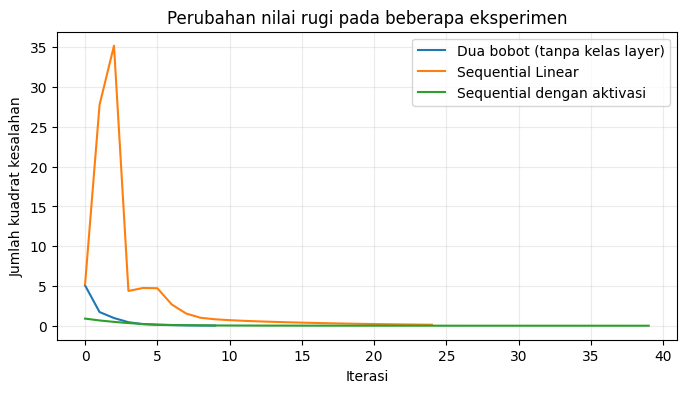

Catatan: arsitektur, inisialisasi, dan laju pembelajaran berbeda;
grafik ini menggambarkan proses masing-masing, bukan perbandingan model yang adil.


In [14]:
plt.figure(figsize=(8, 4))
plt.plot(riwayat_awal, label="Dua bobot (tanpa kelas layer)")
plt.plot(riwayat_linear, label="Sequential Linear")
plt.plot(riwayat_nonlinear, label="Sequential dengan aktivasi")
plt.title("Perubahan nilai rugi pada beberapa eksperimen")
plt.xlabel("Iterasi")
plt.ylabel("Jumlah kuadrat kesalahan")
plt.legend()
plt.grid(alpha=0.25)
plt.show()
print("Catatan: arsitektur, inisialisasi, dan laju pembelajaran berbeda;")
print("grafik ini menggambarkan proses masing-masing, bukan perbandingan model yang adil.")

## 8. *Embedding* dan pemilihan indeks

Layer *embedding* menyimpan satu vektor numerik untuk setiap kata atau kategori. Jika kosakata memiliki `V` kata dan ukuran embedding `D`, bobot embedding berbentuk `(V, D)`.

Contoh dari bab ini memerlukan operator `index_select`: menerima indeks baris dan mengembalikan embedding yang dipilih. Saat *backward*, gradien dikembalikan ke baris yang bersesuaian; **indeks berulang mengakumulasi gradien beberapa kali**.

In [15]:
embedding_uji = Tensor(np.eye(5), autograd=True)
indeks_uji = Tensor([[1,2,3], [2,3,4]])
keluaran_indeks = embedding_uji.index_select(indeks_uji)
keluaran_indeks.sum().backward()
print("Bentuk keluaran indeks:", keluaran_indeks.data.shape)
print("Gradien pada matriks identitas:\n", embedding_uji.grad.data)
assert np.allclose(embedding_uji.grad.data[2], 2)
assert np.allclose(embedding_uji.grad.data[3], 2)

Bentuk keluaran indeks: (2, 3, 5)
Gradien pada matriks identitas:
 [[0. 0. 0. 0. 0.]
 [1. 1. 1. 1. 1.]
 [2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2.]
 [1. 1. 1. 1. 1.]]


In [16]:
class Embedding(Layer):
    def __init__(self, vocab_size, dim):
        self.vocab_size = int(vocab_size)
        self.dim = int(dim)
        inisialisasi = (np.random.rand(self.vocab_size, self.dim) - 0.5) / self.dim
        self.weight = Tensor(inisialisasi, autograd=True)

    def forward(self, input):
        return self.weight.index_select(input)

    def get_parameters(self):
        return [self.weight]

np.random.seed(5)
embed_contoh = Embedding(vocab_size=5, dim=3)
print("Bentuk parameter:", embed_contoh.weight.data.shape)
print("Vektor untuk indeks [1,2,1]:\n", embed_contoh.forward(Tensor([1,2,1])).data)

Bentuk parameter: (5, 3)
Vektor untuk indeks [1,2,1]:
 [[ 0.1395 -0.0039  0.0372]
 [ 0.0886  0.0061 -0.0677]
 [ 0.1395 -0.0039  0.0372]]


## 9. Entropi silang (*cross-entropy*)

Untuk klasifikasi beberapa kelas, keluaran `Linear` adalah **logit**, bukan probabilitas. Fungsi rugi entropi silang mengubah logit melalui *softmax* dan menilai probabilitas kelas target.

\[
p_{i,k} = \frac{e^{z_{i,k}}}{\sum_j e^{z_{i,j}}}, \quad
L = -\frac{1}{N}\sum_{i=1}^{N} \log p_{i,y_i}
\]

Gradien gabungan yang efisien:

\[\frac{\partial L}{\partial z_{i,k}}=\frac{p_{i,k}-\mathbf{1}[k=y_i]}{N}\]

**Penyesuaian numerik:** logit dikurangi nilai maksimum sebelum eksponensial. Gradien juga dibagi banyaknya sampel `N` agar benar-benar sesuai dengan definisi **rata-rata** loss; pada cuplikan buku, faktor ini tidak ditampilkan secara eksplisit.

In [17]:
class CrossEntropyLoss(Layer):
    def forward(self, input, target):
        return input.cross_entropy(target)

rng = np.random.default_rng(7)
logit_awal = rng.normal(size=(4,3))
label_awal = np.array([0,2,1,2])
logit_t = Tensor(logit_awal, autograd=True)
ce = CrossEntropyLoss()
rugi_ce = ce.forward(logit_t, Tensor(label_awal))
rugi_ce.backward()

def ce_numpy(logit):
    z = logit - logit.max(axis=1,keepdims=True)
    p = np.exp(z) / np.exp(z).sum(axis=1,keepdims=True)
    return -np.log(p[np.arange(4),label_awal]).mean()

beda_ce = np.max(np.abs(logit_t.grad.data -
                        cek_gradien_numerik(ce_numpy, logit_awal)))
print("Rugi cross entropy:", round(float(rugi_ce.data), 6))
print("Selisih gradien cross entropy:", f"{beda_ce:.2e}")
assert beda_ce < 1e-6

Rugi cross entropy: 0.939932
Selisih gradien cross entropy: 8.13e-12


### 9.1 Klasifikasi memakai Embedding dan CrossEntropyLoss

Kita melatih model agar indeks masukan `1` dan `2` berhubungan dengan target kelas `0` dan `1`, sama seperti gagasan percobaan pada buku halaman 259. Model langsung mengeluarkan logit; *softmax* dihitung di dalam fungsi rugi.

In [18]:
np.random.seed(0)
data_kelas = Tensor([1,2,1,2])
target_kelas = Tensor([0,1,0,1])
model_kelas = Sequential([Embedding(3,3), Tanh(), Linear(3,4)])
kriteria_ce = CrossEntropyLoss()
optim_kelas = SGD(model_kelas.get_parameters(), alpha=0.1)
riwayat_ce = []

for i in range(120):
    logit = model_kelas.forward(data_kelas)
    rugi = kriteria_ce.forward(logit, target_kelas)
    riwayat_ce.append(float(rugi.data))
    rugi.backward()
    optim_kelas.step()

prediksi_kelas = model_kelas.forward(data_kelas).data.argmax(axis=1)
print("Rugi awal/akhir:", round(riwayat_ce[0],4), "/", round(riwayat_ce[-1],4))
print("Kelas target  :", target_kelas.data.astype(int))
print("Kelas prediksi:", prediksi_kelas)
print("Akurasi       :", np.mean(prediksi_kelas == target_kelas.data))
assert riwayat_ce[-1] < riwayat_ce[0]

Rugi awal/akhir: 1.3511 / 0.0769
Kelas target  : [0 1 0 1]
Kelas prediksi: [0 1 0 1]
Akurasi       : 1.0


## 10. Membangun layer jaringan saraf berulang (`RNNCell`)

Bab 13 menghubungkan kembali materi Bab 12. Satu sel RNN menerima dua masukan: embedding kata saat ini dan kondisi tersembunyi (*hidden state*) dari langkah sebelumnya.

\[
h_t = \phi(x_t W_{ih} + h_{t-1} W_{hh} + b)
\]
\[
o_t = h_t W_{ho} + b_o
\]

Di bawah ini, `RNNCell` dibuat dari tiga `Linear`: masukan-ke-hidden (`w_ih`), hidden-ke-hidden (`w_hh`), hidden-ke-keluaran (`w_ho`). Dengan grafik dinamis, gradien merambat otomatis melintasi langkah waktu (*backpropagation through time*).

> Contoh latihan bab menggunakan sebuah tugas pemodelan kata sederhana dari data **bAbI**. Buku bukan sedang mengajarkan sistem tanya-jawabnya, melainkan memakai kalimat dari dataset tersebut untuk mempelajari prediksi kata dalam urutan.

In [19]:
class RNNCell(Layer):
    def __init__(self, n_inputs, n_hidden, n_output, activation="sigmoid"):
        self.n_inputs = int(n_inputs)
        self.n_hidden = int(n_hidden)
        self.n_output = int(n_output)
        if activation == "sigmoid":
            self.activation = Sigmoid()
        elif activation == "tanh":
            self.activation = Tanh()
        else:
            raise ValueError("Aktivasi harus 'sigmoid' atau 'tanh'.")
        self.w_ih = Linear(n_inputs, n_hidden)
        self.w_hh = Linear(n_hidden, n_hidden)
        self.w_ho = Linear(n_hidden, n_output)

    def forward(self, input, hidden):
        gabungan = self.w_ih.forward(input) + self.w_hh.forward(hidden)
        hidden_baru = self.activation.forward(gabungan)
        output = self.w_ho.forward(hidden_baru)
        return output, hidden_baru

    def init_hidden(self, batch_size=1):
        return Tensor(np.zeros((batch_size, self.n_hidden)))

np.random.seed(1)
uji_rnn = RNNCell(n_inputs=3, n_hidden=5, n_output=7, activation="tanh")
keluaran_rnn, hidden_rnn = uji_rnn.forward(Tensor(np.ones((2,3))), uji_rnn.init_hidden(2))
print("Bentuk keluaran:", keluaran_rnn.data.shape)
print("Bentuk hidden state:", hidden_rnn.data.shape)
assert keluaran_rnn.data.shape == (2,7)
assert hidden_rnn.data.shape == (2,5)

Bentuk keluaran: (2, 7)
Bentuk hidden state: (2, 5)


## 11. Menyiapkan data bAbI untuk pelatihan RNN

Dalam contoh buku, dipakai kira-kira 1.000 baris awal berisi kalimat/pernyataan sederhana. Kalimat dibuat menjadi 6 token dengan token pengisi `-`; model kemudian membaca 5 kata pertama untuk menebak kata keenam.

Notebook akan **mencoba mengambil dataset bAbI dari repositori kode pendamping buku**. Jika unduhan tidak berhasil, notebook dapat berlanjut menggunakan **data simulasi buatan sendiri**, dan sumber yang aktif selalu ditampilkan. Data simulasi hanya alat agar kode bisa diuji secara luring (tujuan lokasi diatur bergantung pada nama pelaku); hasilnya **tidak boleh dilaporkan sebagai hasil bAbI asli**.

Catatan perubahan terhadap buku: tanda baca dibersihkan dan kalimat panjang dipotong menjadi enam token pertama sehingga array memiliki bentuk yang konsisten; ini dibuat eksplisit agar tidak terjadi galat karena panjang kalimat yang berbeda.

In [20]:
from urllib.request import Request, urlopen
import re

SUMBER_BABI = (
    "https://raw.githubusercontent.com/iamtrask/Grokking-Deep-Learning/"
    "master/tasksv11/en/qa1_single-supporting-fact_train.txt"
)

def olah_baris_babi(b):
    # Format dataset: nomor baris, teks; pertanyaan juga mengandung tab dan jawaban.
    b = re.sub(r"^\s*\d+\s+", "", b.strip().lower())
    bagian = b.split("\t")
    teks = bagian[0]
    if len(bagian) > 1:
        teks += " " + bagian[1]
    return re.sub(r"[^a-z\s]", " ", teks).split()

def data_simulasi(jumlah=1000):
    rng = np.random.default_rng(19)
    pelaku = ["mary", "john", "sandra", "daniel"]
    kerja = ["moved", "journeyed", "went", "travelled"]
    tujuan = {"mary": "office", "john": "garden",
              "sandra": "kitchen", "daniel": "hallway"}
    hasil = []
    for _ in range(jumlah):
        p = pelaku[rng.integers(len(pelaku))]
        k = kerja[rng.integers(len(kerja))]
        # Simulasi mengandung pola nyata: tujuan dipengaruhi pelaku.
        t = tujuan[p]
        hasil.append([p, k, "to", "the", t])
    return hasil

try:
    permintaan = Request(SUMBER_BABI, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(permintaan, timeout=8) as respons:
        semua = respons.read().decode("utf-8")
    kalimat = [olah_baris_babi(x) for x in semua.splitlines()[:1000]]
    kalimat = [s for s in kalimat if len(s)>=2]
    if len(kalimat)<100:
        raise ValueError("Data bAbI yang berhasil dibaca terlalu sedikit.")
    sumber_aktif = "bAbI dari repositori pendamping buku"
except Exception as error:
    print("Data daring belum dapat diambil:", type(error).__name__)
    kalimat = data_simulasi()
    sumber_aktif = "SIMULASI CADANGAN, bukan bAbI asli"

kalimat_enam = [(["-"] * max(0, 6-len(s)) + s)[:6] for s in kalimat]
kosakata = sorted(set(kata for baris in kalimat_enam for kata in baris))
kata_ke_indeks = {kata: i for i, kata in enumerate(kosakata)}
indeks_ke_kata = {i: kata for kata, i in kata_ke_indeks.items()}
data_urutan = np.array([[kata_ke_indeks[k] for k in s] for s in kalimat_enam], dtype=int)

print("Sumber:", sumber_aktif)
print("Jumlah urutan:", len(data_urutan))
print("Ukuran kosakata:", len(kosakata))
print("Bentuk matriks:", data_urutan.shape)
print("Contoh kalimat:")
for s in kalimat_enam[:4]:
    print(" ", " ".join(s))
assert data_urutan.shape[1] == 6

Sumber: bAbI dari repositori pendamping buku
Jumlah urutan: 1000
Ukuran kosakata: 20
Bentuk matriks: (1000, 6)
Contoh kalimat:
  - mary moved to the bathroom
  - john went to the hallway
  - - where is mary bathroom
  daniel went back to the hallway


### 11.1 Pelatihan RNN: prediksi kata terakhir

Arsitektur mengikuti akhir bab:

`indeks kata → Embedding(16) → RNNCell(hidden=16) → logit kelas → CrossEntropyLoss`

Contoh dalam buku memakai 1.000 iterasi, *batch size* 100, dan `alpha=0,05`. Nilai ini disediakan sebagai konfigurasi bawaan. Notebook memilih aktivasi `tanh` (sedangkan contoh buku memakai `sigmoid`) untuk memperlihatkan alternatif yang sudah didukung `RNNCell`. Tidak diperlukan GPU untuk percobaan kecil ini.

Akurasi di bawah ini dihitung **pada sampel latih yang sama** (bukan akurasi generalisasi ke data tak terlihat). Jika sumber datanya simulasi, interpretasi hasil harus disebut sebagai demonstrasi saja.

In [21]:
np.random.seed(0)
DIMENSI_EMBED = 16
DIMENSI_HIDDEN = 16
BESAR_BATCH = min(100, len(data_urutan))
ITERASI_RNN = 1000      # Sama dengan jumlah iterasi contoh utama Bab 13
LAJU_BELAJAR = 0.05

model_embed = Embedding(vocab_size=len(kosakata), dim=DIMENSI_EMBED)
model_rnn = RNNCell(DIMENSI_EMBED, DIMENSI_HIDDEN, len(kosakata), activation="tanh")
optim_rnn = SGD(model_rnn.get_parameters() + model_embed.get_parameters(), alpha=LAJU_BELAJAR)
kriteria_rnn = CrossEntropyLoss()
riwayat_rnn = []

for langkah in range(ITERASI_RNN):
    hidden = model_rnn.init_hidden(BESAR_BATCH)
    for t in range(5):
        input_indeks = Tensor(data_urutan[:BESAR_BATCH, t])
        input_vektor = model_embed.forward(input_indeks)
        output, hidden = model_rnn.forward(input_vektor, hidden)

    target_akhir = Tensor(data_urutan[:BESAR_BATCH, 5])
    loss = kriteria_rnn.forward(output, target_akhir)
    nilai_loss = float(loss.data)
    akurasi_latih = float(np.mean(output.data.argmax(axis=1) == target_akhir.data))
    riwayat_rnn.append((langkah, nilai_loss, akurasi_latih))
    if langkah % 200 == 0 or langkah == ITERASI_RNN - 1:
        print(f"Langkah {langkah:4d} | rugi={nilai_loss:.4f} | akurasi latih={akurasi_latih:.1%}")
    loss.backward()
    optim_rnn.step()

assert np.isfinite(np.array(riwayat_rnn)).all()

Langkah    0 | rugi=3.1066 | akurasi latih=1.0%
Langkah  200 | rugi=2.0381 | akurasi latih=33.0%
Langkah  400 | rugi=1.9945 | akurasi latih=37.0%
Langkah  600 | rugi=1.9718 | akurasi latih=37.0%
Langkah  800 | rugi=1.9560 | akurasi latih=36.0%
Langkah  999 | rugi=1.9433 | akurasi latih=36.0%


## 12. Evaluasi dan interpretasi hasil

Perlu dibedakan antara:

1. **Rugi pelatihan**: kesalahan model pada kumpulan kecil urutan yang digunakan untuk pembaruan bobot.
2. **Akurasi pelatihan**: bagian kata terakhir yang berhasil ditebak pada urutan latihan yang sama.
3. **Akurasi data baru**: memerlukan kumpulan data terpisah, yang **bukan** fokus demonstrasi di akhir Bab 13.

Contoh buku menunjukkan prediksi lokasi yang masuk akal, tetapi nilai rugi dan akurasi dapat berbeda bila susunan kosakata, inisialisasi parameter, atau data berubah. Notebook ini tidak mengklaim hasil tertentu sebelum kode dijalankan.

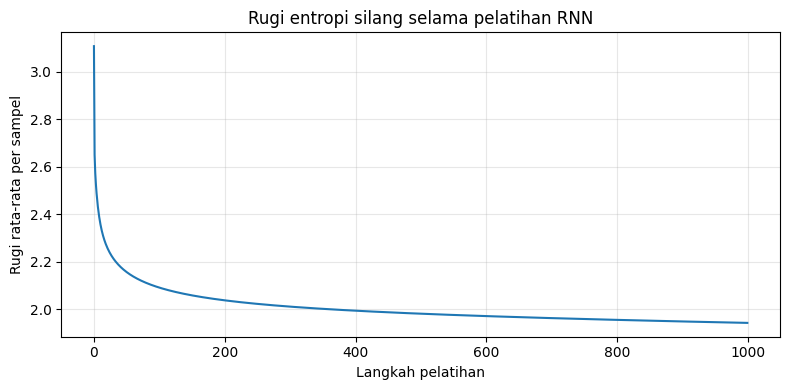

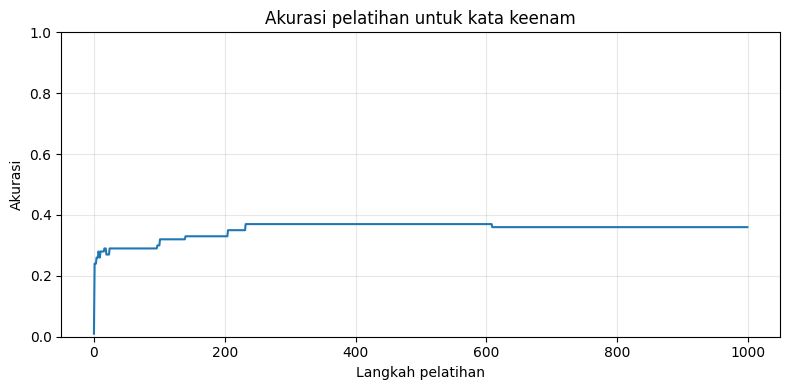

In [22]:
riwayat_array = np.array(riwayat_rnn)
plt.figure(figsize=(8,4))
plt.plot(riwayat_array[:,0], riwayat_array[:,1])
plt.title("Rugi entropi silang selama pelatihan RNN")
plt.xlabel("Langkah pelatihan")
plt.ylabel("Rugi rata-rata per sampel")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,4))
plt.plot(riwayat_array[:,0], riwayat_array[:,2])
plt.title("Akurasi pelatihan untuk kata keenam")
plt.xlabel("Langkah pelatihan")
plt.ylabel("Akurasi")
plt.ylim(0,1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
def tebak_kata_keenam(indeks_5):
    hidden = model_rnn.init_hidden(batch_size=1)
    for indeks in indeks_5:
        emb = model_embed.forward(Tensor([int(indeks)]))
        pred, hidden = model_rnn.forward(emb, hidden)
    pil = int(pred.data.argmax(axis=1)[0])
    return indeks_ke_kata[pil], pred.data.ravel()

print("Sumber evaluasi:", sumber_aktif)
for indeks_baris in [0, 1, 2, 3, 4]:
    baris = data_urutan[indeks_baris]
    konteks = " ".join(indeks_ke_kata[int(i)] for i in baris[:5])
    benar = indeks_ke_kata[int(baris[5])]
    tebakan, _ = tebak_kata_keenam(baris[:5])
    print(f"Konteks: {konteks:<43} | target: {benar:<12} | prediksi: {tebakan}")

Sumber evaluasi: bAbI dari repositori pendamping buku
Konteks: - mary moved to the                         | target: bathroom     | prediksi: bedroom
Konteks: - john went to the                          | target: hallway      | prediksi: bedroom
Konteks: - - where is mary                           | target: bathroom     | prediksi: bathroom
Konteks: daniel went back to the                     | target: hallway      | prediksi: garden
Konteks: - sandra moved to the                       | target: garden       | prediksi: bedroom
